In [1]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from sklearn.model_selection import train_test_split

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Paths
DATA_ROOT = "/Users/Rishab/Research"
TARGET_FOLDER = "IR_drop"

SINGLE_CHANNEL_FOLDERS = [
    "power_all",
    "power_i",
    "power_s",
    "power_sca"
]

MULTI_CHANNEL_FOLDER = "power_t"  # 20 time slices

TARGET_SIZE = (320, 320)
BATCH_SIZE = 16

In [3]:
def compute_channel_min_max(file_list):
    channel_min = None
    channel_max = None

    for rel_path in file_list:
        # rel_path = chip/IR_drop/file.npz

        chip = rel_path.split(os.sep)[0]
        filename = rel_path.split(os.sep)[-1]

        power_maps = []

        # Single-channel inputs
        for folder in SINGLE_CHANNEL_FOLDERS:
            path = os.path.join(DATA_ROOT, chip, folder, filename)

            arr = np.load(path)
            if isinstance(arr, np.lib.npyio.NpzFile):
                arr = list(arr.values())[0]
            arr = arr.astype(np.float32)

            if arr.ndim == 2:
                arr = arr[..., np.newaxis]

            power_maps.append(arr)

        # Multi-channel power_t
        path = os.path.join(DATA_ROOT, chip, MULTI_CHANNEL_FOLDER, filename)

        arr = np.load(path)
        if isinstance(arr, np.lib.npyio.NpzFile):
            arr = list(arr.values())[0]
        arr = arr.astype(np.float32)

        if arr.ndim == 3 and arr.shape[0] == 20:
            arr = np.transpose(arr, (1, 2, 0))

        power_maps.append(arr)

        X = np.concatenate(power_maps, axis=-1)

        sample_min = X.min(axis=(0, 1))
        sample_max = X.max(axis=(0, 1))

        if channel_min is None:
            channel_min = sample_min
            channel_max = sample_max
        else:
            channel_min = np.minimum(channel_min, sample_min)
            channel_max = np.maximum(channel_max, sample_max)

    return channel_min, channel_max

In [4]:
# ----------------------------
# File split
# ----------------------------
CHIPS = [
    "Vortex-small",
    #"Vortex-large",
    #"nvdla-large",
    #"nvdla-small",
    #"openc910-1",
    #"RISCY",
    #"RISCY-FPU",
    #"zero-riscy"
]

TARGET_FOLDER = "IR_drop"

all_files = []
chip_names = []

for chip in CHIPS:
    ir_dir = os.path.join(DATA_ROOT, chip, TARGET_FOLDER)

    for f in sorted(os.listdir(ir_dir)):
        valid = True

        # check all required inputs exist
        for folder in SINGLE_CHANNEL_FOLDERS + [MULTI_CHANNEL_FOLDER]:
            path = os.path.join(DATA_ROOT, chip, folder, f)
            if not os.path.exists(path):
                valid = False
                break

        if valid:
            all_files.append(os.path.join(chip, TARGET_FOLDER, f))
            chip_names.append(chip)

# 80% train, 20% temp
train_files, temp_files, train_labels, temp_labels = train_test_split(
    all_files,
    chip_names,
    test_size=0.2,
    random_state=42,
    stratify=chip_names
)

# split temp → 10% val, 10% test
val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files,
    temp_labels,
    test_size=0.5,
    random_state=42,
    stratify=temp_labels
)

# Compute channel-wise min/max on training set
CHANNEL_MIN, CHANNEL_MAX = compute_channel_min_max(train_files)
CHANNEL_MIN_TF = tf.constant(CHANNEL_MIN, dtype=tf.float32)
CHANNEL_MAX_TF = tf.constant(CHANNEL_MAX, dtype=tf.float32)

print("CHANNEL_MIN:", CHANNEL_MIN)
print("CHANNEL_MAX:", CHANNEL_MAX)

CHANNEL_MIN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
CHANNEL_MAX: [468.28488  267.15247  194.15233  411.86502    0.         0.
   0.       151.57164  129.54085   98.552025 129.40248  351.38638
 293.70135  227.32358  158.85818  134.74515  105.56055   77.014694
  41.137352  32.922947  25.550684  19.602158  14.733725  12.15556 ]


In [5]:
for chip in CHIPS:
    path = os.path.join(DATA_ROOT, chip, TARGET_FOLDER)
    print(chip, len(os.listdir(path)))

Vortex-small 96


In [6]:
for chip in CHIPS:
    vals = []

    chip_files = [f for f in all_files if f.startswith(chip)]

    for rel in chip_files:
        arr = np.load(os.path.join(DATA_ROOT, rel))
        if isinstance(arr, np.lib.npyio.NpzFile):
            arr = list(arr.values())[0]
        vals.append(arr.max())

    print(chip, np.max(vals), np.mean(vals))

Vortex-small 1386.04 349.9682604166666


In [7]:
# ----------------------------
# STEP 2: Dataset loader with channel-wise normalization
# ----------------------------
def load_npy(path):
    def _load(path):
        arr_file = np.load(path.decode("utf-8"))
        if isinstance(arr_file, np.lib.npyio.NpzFile):
            arr = list(arr_file.values())[0]
        else:
            arr = arr_file
        arr = arr.astype(np.float32)
        if arr.ndim == 2:
            arr = arr[..., np.newaxis]
        return arr

    tensor = tf.numpy_function(_load, [path], tf.float32)
    tensor.set_shape([None, None, None])
    tensor = tf.image.resize(tensor, TARGET_SIZE)
    return tensor

In [8]:
def load_sample(rel_path):
    # rel_path = "chip_name/IR_drop/file.npz"

    y_path = tf.strings.join([DATA_ROOT, rel_path], separator=os.sep)
    y = load_npy(y_path)
    #y = tf.clip_by_value(y, 0.0, 30.0)

    chip = tf.strings.split(rel_path, os.sep)[0]
    filename = tf.strings.split(rel_path, os.sep)[-1]

    power_maps = []

    # single-channel inputs
    for folder in SINGLE_CHANNEL_FOLDERS:
        x_path = tf.strings.join(
            [DATA_ROOT, chip, folder, filename],
            separator=os.sep
        )
        x = load_npy(x_path)
        power_maps.append(x)

    # multi-channel
    power_t_path = tf.strings.join(
        [DATA_ROOT, chip, MULTI_CHANNEL_FOLDER, filename],
        separator=os.sep
    )

    def load_power_t(path):
        arr_file = np.load(path.decode("utf-8"))
        if isinstance(arr_file, np.lib.npyio.NpzFile):
            arr = list(arr_file.values())[0]
        else:
            arr = arr_file
        arr = arr.astype(np.float32)
        if arr.ndim == 3 and arr.shape[0] == 20:
            arr = np.transpose(arr, (1, 2, 0))
        return arr

    power_t = tf.numpy_function(load_power_t, [power_t_path], tf.float32)
    power_t.set_shape([None, None, 20])
    power_t = tf.image.resize(power_t, TARGET_SIZE)

    power_maps.append(power_t)

    X = tf.concat(power_maps, axis=-1)

    # normalize
    X = (X - CHANNEL_MIN_TF) / (CHANNEL_MAX_TF - CHANNEL_MIN_TF + 1e-8)

    return X, y

In [9]:
# ----------------------------
# STEP 3: Build datasets
# ----------------------------
train_dataset = (
    tf.data.Dataset.from_tensor_slices(train_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(len(train_files))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices(val_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices(test_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [10]:
def compute_global_max(dataset):
    global_max = 0.0

    for _, y_batch in dataset:
        batch_max = tf.reduce_max(y_batch)
        global_max = max(global_max, float(batch_max))

    return global_max

train_max = compute_global_max(train_dataset)
val_max   = compute_global_max(val_dataset)
test_max  = compute_global_max(test_dataset)

print("Train max:", train_max)
print("Val max:", val_max)
print("Test max:", test_max)

Train max: 1272.948974609375
Val max: 492.3973693847656
Test max: 605.6441040039062


In [11]:
print("Train:", len(train_files))
print("Val:", len(val_files))
print("Test:", len(test_files))

for X, y in train_dataset.take(1):
    print("X:", X.shape)  # (B, 300, 300, 24)
    print("y:", y.shape)  # (B, 300, 300, 1)

Train: 76
Val: 10
Test: 10


X: (16, 320, 320, 24)
y: (16, 320, 320, 1)


In [12]:
import ssl
import certifi

ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

In [13]:
from tensorflow.keras.applications import ResNet50V2

def build_24_channel_model(input_shape=(320, 320, 24)):

    img_input = layers.Input(shape=input_shape)

    # 24 → 3 adapter
    adapter = layers.Conv2D(
        3,
        (3, 3),
        padding='same',
        name='channel_adapter'
    )(img_input)

    # Backbone
    base_model = ResNet50V2(
        include_top=False,
        weights='imagenet',
        input_shape=(320, 320, 3)
    )

    # INITIAL TRAINING:
    # freeze backbone
    base_model.trainable = False

    x = base_model(adapter, training=False)

    # Decoder
    x = layers.Conv2D(256, 3, padding='same', activation='relu')(x)
    x = layers.UpSampling2D((2,2))(x)

    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.UpSampling2D((2,2))(x)

    x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = layers.UpSampling2D((2,2))(x)

    x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
    x = layers.UpSampling2D((2,2))(x)

    x = layers.Conv2D(16, 3, padding='same', activation='relu')(x)
    x = layers.UpSampling2D((2,2))(x)

    output = layers.Conv2D(1, 1, activation='linear')(x)

    model = models.Model(inputs=img_input, outputs=output)

    return model, base_model

model, base_model = build_24_channel_model()

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 320, 320, 24)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ channel_adapter (Conv2D)        │ (None, 320, 320, 3)    │           651 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 10, 10, 2048)   │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 10, 10, 256)    │     4,718,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 20, 128)    │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 80, 80, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_4 (UpSampling2D)  │ (None, 320, 320, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 320, 320, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,676,236 (109.39 MB)

 Trainable params: 5,111,436 (19.50 MB)

 Non-trainable params: 23,564,800 (89.89 MB)

In [14]:
import time

# =========================================================
# TIMER CALLBACK
# =========================================================

class TimeHistory(tf.keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.time() - self.epoch_start_time
        self.times.append(elapsed)

        print(
            f"\nEpoch {epoch + 1} took "
            f"{elapsed:.2f} seconds "
            f"({elapsed/60:.2f} minutes)"
        )


time_callback_stage1 = TimeHistory()
time_callback_stage2 = TimeHistory()


# =========================================================
# TOTAL TIMER START
# =========================================================

total_start = time.time()


# =========================================================
# CALLBACKS — STAGE 1
# =========================================================

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_stage1 = tf.keras.callbacks.ModelCheckpoint(
    "best_stage1.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


# =========================================================
# STAGE 1:
# TRAIN DECODER + ADAPTER ONLY
# =========================================================

print("\n========================================")
print("STAGE 1: TRAINING DECODER")
print("========================================\n")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='log_cosh',
    metrics=['mae']
)

stage1_start = time.time()

history_stage1 = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint_stage1,
        time_callback_stage1
    ]
)

stage1_end = time.time()

print("\n========================================")
print("STAGE 1 COMPLETE")
print("========================================")
print(f"Stage 1 total time: {(stage1_end - stage1_start):.2f} seconds")
print(f"Stage 1 total time: {(stage1_end - stage1_start)/60:.2f} minutes")

avg_stage1_epoch = sum(time_callback_stage1.times) / len(time_callback_stage1.times)

print(f"Average Stage 1 epoch time: {avg_stage1_epoch:.2f} seconds")


# =========================================================
# LOAD BEST STAGE 1 WEIGHTS
# =========================================================

model.load_weights("best_stage1.keras")


# =========================================================
# STAGE 2:
# FINE-TUNE BACKBONE
# =========================================================

print("\n========================================")
print("STAGE 2: FINE-TUNING BACKBONE")
print("========================================\n")

# Unfreeze backbone
base_model.trainable = True

# Freeze MOST layers
for layer in base_model.layers[:-10]:
    layer.trainable = False

# Keep BatchNorm frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False


# IMPORTANT:
# recompile AFTER changing trainable flags
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='log_cosh',
    metrics=['mae']
)


# =========================================================
# CALLBACKS — STAGE 2
# =========================================================

early_stop_ft = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr_ft = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_stage2 = tf.keras.callbacks.ModelCheckpoint(
    "best_finetuned.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


# =========================================================
# STAGE 2 TRAINING
# =========================================================

stage2_start = time.time()

history_finetune = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        early_stop_ft,
        reduce_lr_ft,
        checkpoint_stage2,
        time_callback_stage2
    ]
)

stage2_end = time.time()

print("\n========================================")
print("STAGE 2 COMPLETE")
print("========================================")
print(f"Stage 2 total time: {(stage2_end - stage2_start):.2f} seconds")
print(f"Stage 2 total time: {(stage2_end - stage2_start)/60:.2f} minutes")

avg_stage2_epoch = sum(time_callback_stage2.times) / len(time_callback_stage2.times)

print(f"Average Stage 2 epoch time: {avg_stage2_epoch:.2f} seconds")


# =========================================================
# LOAD BEST FINETUNED WEIGHTS
# =========================================================

model.load_weights("best_finetuned.keras")


# =========================================================
# SAVE FINAL MODEL
# =========================================================

print("Sweep run: final model save skipped; best checkpoints retained.")


# =========================================================
# TOTAL RUNTIME
# =========================================================

total_end = time.time()

total_seconds = total_end - total_start

print("\n========================================")
print("TRAINING COMPLETE")
print("========================================")

print(f"Total runtime: {total_seconds:.2f} seconds")
print(f"Total runtime: {total_seconds/60:.2f} minutes")
print(f"Total runtime: {total_seconds/3600:.2f} hours")


STAGE 1: TRAINING DECODER

Epoch 1/20


1/5 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - loss: 5.6922 - mae: 6.2168

2/5 ━━━━━━━━━━━━━━━━━━━━ 2s 879ms/step - loss: 5.7215 - mae: 6.2743

3/5 ━━━━━━━━━━━━━━━━━━━━ 1s 879ms/step - loss: 5.6994 - mae: 6.2557

4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 879ms/step - loss: 5.6970 - mae: 6.2581

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 832ms/step - loss: 5.6944 - mae: 6.2589

... (345 outputs left out)


Epoch 20: finished saving model to best_finetuned.keras



Epoch 20 took 5.52 seconds (0.09 minutes)
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - loss: 4.1667 - mae: 4.6300 - val_loss: 4.6239 - val_mae: 5.0883 - learning_rate: 2.5000e-04



STAGE 2 COMPLETE
Stage 2 total time: 112.09 seconds
Stage 2 total time: 1.87 minutes
Average Stage 2 epoch time: 5.60 seconds


Sweep run: final model save skipped; best checkpoints retained.

TRAINING COMPLETE
Total runtime: 225.41 seconds
Total runtime: 3.76 minutes
Total runtime: 0.06 hours


In [15]:
# Evaluate on train, val, test
train_metrics = model.evaluate(train_dataset)
val_metrics   = model.evaluate(val_dataset)
test_metrics  = model.evaluate(test_dataset)

print("Train metrics (loss, MAE):", train_metrics)
print("Val metrics (loss, MAE):", val_metrics)
print("Test metrics (loss, MAE):", test_metrics)

1/5 ━━━━━━━━━━━━━━━━━━━━ 3s 863ms/step - loss: 3.9708 - mae: 4.4446

2/5 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - loss: 4.1309 - mae: 4.6051

3/5 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - loss: 4.1457 - mae: 4.6189

4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step - loss: 4.1618 - mae: 4.6340

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 276ms/step - loss: 4.1554 - mae: 4.6263

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 276ms/step - loss: 4.1295 - mae: 4.5956


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - loss: 4.6239 - mae: 5.0883

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - loss: 4.6239 - mae: 5.0883


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - loss: 4.2239 - mae: 4.6965

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - loss: 4.2239 - mae: 4.6965


Train metrics (loss, MAE): [4.129471302032471, 4.595608711242676]
Val metrics (loss, MAE): [4.623851299285889, 5.0882887840271]
Test metrics (loss, MAE): [4.223883152008057, 4.696499824523926]


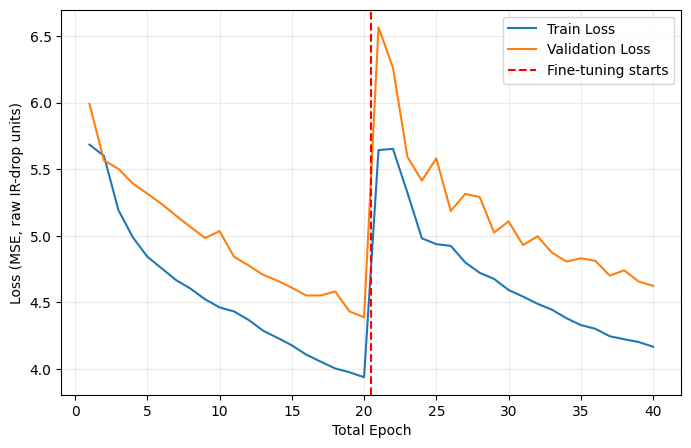

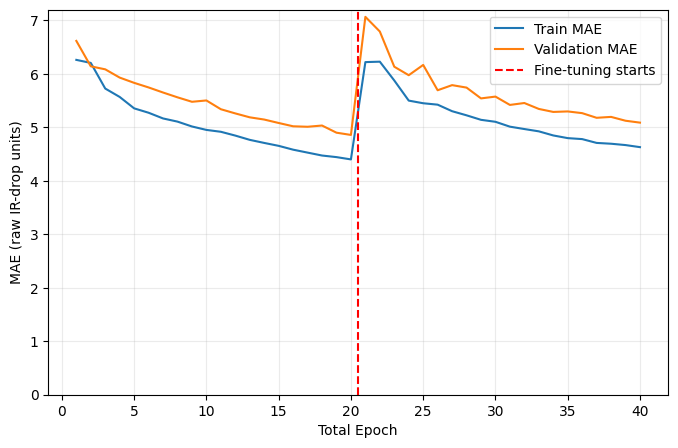

In [16]:
train_loss = history_stage1.history['loss'] + history_finetune.history['loss']
val_loss = history_stage1.history['val_loss'] + history_finetune.history['val_loss']
epochs = range(1, len(train_loss) + 1)
stage_boundary = len(history_stage1.history['loss'])

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label='Train Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.axvline(
    x=stage_boundary + 0.5,
    color='red',
    linestyle='--',
    label='Fine-tuning starts'
)
plt.xlabel('Total Epoch')
plt.ylabel('Loss (MSE, raw IR-drop units)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

train_mae = history_stage1.history['mae'] + history_finetune.history['mae']
val_mae = history_stage1.history['val_mae'] + history_finetune.history['val_mae']
epochs = range(1, len(train_mae) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_mae, label='Train MAE')
plt.plot(epochs, val_mae, label='Validation MAE')
plt.axvline(
    x=stage_boundary + 0.5,
    color='red',
    linestyle='--',
    label='Fine-tuning starts'
)
plt.xlabel('Total Epoch')
plt.ylabel('MAE (raw IR-drop units)')
plt.legend()
plt.ylim(bottom=0)
plt.grid(alpha=0.25)
plt.show()


In [17]:
# =========================================================
# RAW-Y METRICS BLOCK
# Use for:
#   fft-strat-all.ipynb
#   fft-strat-all-no_outliers.ipynb
#
# This prints:
#   1. Combined metrics:
#        - global/test-set range
#        - per-chip range
#        - per-image range
#   2. Equal-weight chip average:
#        - global/test-set range
#        - per-chip range
#        - per-image range
#   3. Each chip:
#        - global/test-set range
#        - per-chip range
#        - per-image range
# =========================================================

chip_results = {}
all_preds = []
all_truth = []
all_chips = []

# -----------------------------
# Collect predictions grouped by chip
# -----------------------------
for batch_idx, (x_batch, y_batch) in enumerate(test_dataset):

    preds = model.predict(x_batch, verbose=0)

    batch_size = preds.shape[0]

    start_idx = batch_idx * BATCH_SIZE
    end_idx = start_idx + batch_size

    batch_files = test_files[start_idx:end_idx]

    for i in range(batch_size):

        chip = batch_files[i].split(os.sep)[0]

        pred = preds[i]
        truth = y_batch[i].numpy()

        if chip not in chip_results:
            chip_results[chip] = {
                "preds": [],
                "truth": []
            }

        chip_results[chip]["preds"].append(pred)
        chip_results[chip]["truth"].append(truth)

        all_preds.append(pred)
        all_truth.append(truth)
        all_chips.append(chip)


# =========================================================
# Helper functions
# =========================================================

def flatten_arrays(arrays):
    return np.array(arrays).flatten()


def get_range_from_arrays(arrays):
    arrays = np.array(arrays)
    return float(arrays.max() - arrays.min())


def compute_base_metrics(preds, truth):
    preds = np.array(preds)
    truth = np.array(truth)

    pred_flat = preds.flatten()
    truth_flat = truth.flatten()

    mae = np.mean(np.abs(pred_flat - truth_flat))
    rmse = np.sqrt(np.mean((pred_flat - truth_flat) ** 2))

    max_ir = truth_flat.max()

    nmae = mae / (max_ir + 1e-8)
    rrmse = rmse / (max_ir + 1e-8)

    maxe = np.max(np.abs(pred_flat - truth_flat))

    ss_res = np.sum((truth_flat - pred_flat) ** 2)
    ss_tot = np.sum((truth_flat - np.mean(truth_flat)) ** 2)

    if ss_tot == 0:
        r2 = np.nan
    else:
        r2 = 1 - (ss_res / ss_tot)

    return mae, nmae, rmse, rrmse, maxe, r2


def compute_ssim_psnr_global_range(preds, truth, global_data_range):
    # Uses ONE data range for everything.
    # For combined metrics, this matches your old global/test-set range idea.
    preds = np.array(preds)
    truth = np.array(truth)

    pred_flat = preds.flatten()
    truth_flat = truth.flatten()

    rmse = np.sqrt(np.mean((pred_flat - truth_flat) ** 2))

    psnr = 20 * np.log10(global_data_range / (rmse + 1e-8))

    ssim_vals = tf.image.ssim(
        tf.convert_to_tensor(truth, dtype=tf.float32),
        tf.convert_to_tensor(preds, dtype=tf.float32),
        max_val=global_data_range
    ).numpy()

    return np.mean(ssim_vals), psnr


def compute_ssim_psnr_single_group_range(preds, truth):
    # Uses the range of the passed-in group.
    # If the group is one chip, this is per-chip range.
    # If the group is all test samples, this is global/test-set range.
    data_range = get_range_from_arrays(truth)

    return compute_ssim_psnr_global_range(
        preds,
        truth,
        data_range
    )


def compute_ssim_psnr_per_chip_range(preds, truth, chips):
    # Uses each chip's own data range.
    # For combined metrics, each image is evaluated using its chip's range.
    # For one-chip metrics, this becomes the same as that chip's group range.
    preds = np.array(preds)
    truth = np.array(truth)
    chips = np.array(chips)

    ssim_vals = []
    psnr_vals = []

    for chip in np.unique(chips):

        idx = np.where(chips == chip)[0]

        chip_preds = preds[idx]
        chip_truth = truth[idx]

        chip_range = get_range_from_arrays(chip_truth)

        if chip_range <= 0:
            continue

        chip_ssim_vals = tf.image.ssim(
            tf.convert_to_tensor(chip_truth, dtype=tf.float32),
            tf.convert_to_tensor(chip_preds, dtype=tf.float32),
            max_val=chip_range
        ).numpy()

        chip_rmse = np.sqrt(np.mean((chip_preds - chip_truth) ** 2))
        chip_psnr = 20 * np.log10(chip_range / (chip_rmse + 1e-8))

        ssim_vals.extend(list(chip_ssim_vals))
        psnr_vals.extend([chip_psnr] * len(idx))

    return np.mean(ssim_vals), np.mean(psnr_vals)


def compute_ssim_psnr_per_image_range(preds, truth):
    # Uses each image's own data range.
    # This is the strictest SSIM/PSNR version.
    preds = np.array(preds)
    truth = np.array(truth)

    ssim_vals = []
    psnr_vals = []

    for p, t in zip(preds, truth):

        image_range = float(t.max() - t.min())

        if image_range <= 0:
            continue

        ssim_val = tf.image.ssim(
            tf.convert_to_tensor(t[None, ...], dtype=tf.float32),
            tf.convert_to_tensor(p[None, ...], dtype=tf.float32),
            max_val=image_range
        ).numpy()[0]

        image_rmse = np.sqrt(np.mean((p - t) ** 2))
        image_psnr = 20 * np.log10(image_range / (image_rmse + 1e-8))

        ssim_vals.append(ssim_val)
        psnr_vals.append(image_psnr)

    return np.mean(ssim_vals), np.mean(psnr_vals)


def compute_metrics(preds, truth, chips, range_mode, global_data_range=None):
    mae, nmae, rmse, rrmse, maxe, r2 = compute_base_metrics(preds, truth)

    if range_mode == "global":
        ssim_score, psnr = compute_ssim_psnr_global_range(
            preds,
            truth,
            global_data_range
        )

    elif range_mode == "per_chip":
        ssim_score, psnr = compute_ssim_psnr_per_chip_range(
            preds,
            truth,
            chips
        )

    elif range_mode == "per_image":
        ssim_score, psnr = compute_ssim_psnr_per_image_range(
            preds,
            truth
        )

    else:
        raise ValueError("range_mode must be 'global', 'per_chip', or 'per_image'")

    return {
        "SSIM": ssim_score,
        "MAE": mae,
        "NMAE": nmae,
        "RMSE": rmse,
        "rRMSE": rrmse,
        "MaxE": maxe,
        "PSNR": psnr,
        "R2": r2
    }


def print_metrics(title, metrics):
    print("\n==============================")
    print(title)
    print("==============================")

    for k, v in metrics.items():
        print(f"{k:8}: {v:.6f}")


# =========================================================
# Global/test-set range
# =========================================================

global_data_range = get_range_from_arrays(all_truth)

print("\n============================================================")
print("GLOBAL / TEST-SET DATA RANGE")
print("============================================================")
print(f"Global data range: {global_data_range:.6f}")


# =========================================================
# 1. Combined metrics
# =========================================================

combined_global = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="global",
    global_data_range=global_data_range
)

combined_per_chip = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="per_chip",
    global_data_range=global_data_range
)

combined_per_image = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="per_image",
    global_data_range=global_data_range
)

print_metrics("COMBINED TEST METRICS - GLOBAL / TEST-SET RANGE", combined_global)
print_metrics("COMBINED TEST METRICS - PER-CHIP RANGE", combined_per_chip)
print_metrics("COMBINED TEST METRICS - PER-IMAGE RANGE", combined_per_image)


# =========================================================
# 2. Equal-weight chip averages
# =========================================================

per_chip_metrics_global = {}
per_chip_metrics_per_chip = {}
per_chip_metrics_per_image = {}

for chip in CHIPS:

    chip_preds = chip_results[chip]["preds"]
    chip_truth = chip_results[chip]["truth"]
    chip_labels = [chip] * len(chip_preds)

    per_chip_metrics_global[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="global",
        global_data_range=global_data_range
    )

    per_chip_metrics_per_chip[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="per_chip",
        global_data_range=global_data_range
    )

    per_chip_metrics_per_image[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="per_image",
        global_data_range=global_data_range
    )


def compute_equal_weight_average(per_chip_metrics):
    avg_metrics = {}

    for metric_name in per_chip_metrics[CHIPS[0]]:
        avg_metrics[metric_name] = np.mean([
            per_chip_metrics[chip][metric_name]
            for chip in CHIPS
        ])

    return avg_metrics


equal_weight_global = compute_equal_weight_average(per_chip_metrics_global)
equal_weight_per_chip = compute_equal_weight_average(per_chip_metrics_per_chip)
equal_weight_per_image = compute_equal_weight_average(per_chip_metrics_per_image)

print_metrics("EQUAL-WEIGHT CHIP AVERAGE - GLOBAL / TEST-SET RANGE", equal_weight_global)
print_metrics("EQUAL-WEIGHT CHIP AVERAGE - PER-CHIP RANGE", equal_weight_per_chip)
print_metrics("EQUAL-WEIGHT CHIP AVERAGE - PER-IMAGE RANGE", equal_weight_per_image)


# =========================================================
# 3. Each chip, with all three SSIM/PSNR range definitions
# =========================================================

for chip in CHIPS:

    print("\n############################################################")
    print(f"CHIP: {chip}")
    print("############################################################")

    print_metrics(
        f"{chip} - GLOBAL / TEST-SET RANGE",
        per_chip_metrics_global[chip]
    )

    print_metrics(
        f"{chip} - PER-CHIP RANGE",
        per_chip_metrics_per_chip[chip]
    )

    print_metrics(
        f"{chip} - PER-IMAGE RANGE",
        per_chip_metrics_per_image[chip]
    )


GLOBAL / TEST-SET DATA RANGE
Global data range: 605.644104



COMBINED TEST METRICS - GLOBAL / TEST-SET RANGE
SSIM    : 0.831750
MAE     : 4.696500
NMAE    : 0.007755
RMSE    : 11.897553
rRMSE   : 0.019644
MaxE    : 603.612000
PSNR    : 34.135197
R2      : 0.169482

COMBINED TEST METRICS - PER-CHIP RANGE
SSIM    : 0.831750
MAE     : 4.696500
NMAE    : 0.007755
RMSE    : 11.897553
rRMSE   : 0.019644
MaxE    : 603.612000
PSNR    : 34.135197
R2      : 0.169482

COMBINED TEST METRICS - PER-IMAGE RANGE
SSIM    : 0.708476
MAE     : 4.696500
NMAE    : 0.007755
RMSE    : 11.897553
rRMSE   : 0.019644
MaxE    : 603.612000
PSNR    : 28.655634
R2      : 0.169482



EQUAL-WEIGHT CHIP AVERAGE - GLOBAL / TEST-SET RANGE
SSIM    : 0.831750
MAE     : 4.696500
NMAE    : 0.007755
RMSE    : 11.897553
rRMSE   : 0.019644
MaxE    : 603.612000
PSNR    : 34.135197
R2      : 0.169482

EQUAL-WEIGHT CHIP AVERAGE - PER-CHIP RANGE
SSIM    : 0.831750
MAE     : 4.696500
NMAE    : 0.007755
RMSE    : 11.897553
rRMSE   : 0.019644
MaxE    : 603.612000
PSNR    : 34.135197
R2      : 0.169482

EQUAL-WEIGHT CHIP AVERAGE - PER-IMAGE RANGE
SSIM    : 0.708476
MAE     : 4.696500
NMAE    : 0.007755
RMSE    : 11.897553
rRMSE   : 0.019644
MaxE    : 603.612000
PSNR    : 28.655634
R2      : 0.169482

############################################################
CHIP: Vortex-small
############################################################

Vortex-small - GLOBAL / TEST-SET RANGE
SSIM    : 0.831750
MAE     : 4.696500
NMAE    : 0.007755
RMSE    : 11.897553
rRMSE   : 0.019644
MaxE    : 603.612000
PSNR    : 34.135197
R2      : 0.169482

Vortex-small - PER-CHIP RANGE
SSIM    : 0.831750
MA

In [18]:
# =========================================================
# RANDOM SAMPLE PER CHIP
# =========================================================

import random

samples_per_chip = 3   # change if you want more/fewer examples

chip_sample_indices = {}

for chip in CHIPS:

    # indices belonging to this chip
    chip_indices = [
        i for i in range(len(test_files))
        if test_files[i].split(os.sep)[0] == chip
    ]

    # randomly sample from that chip
    chip_sample_indices[chip] = random.sample(
        chip_indices,
        min(samples_per_chip, len(chip_indices))
    )


Vortex-small

Pred range : -1.2998921 22.068592
Truth range: 0.0 251.51474


/var/folders/4w/2t_442ks2gn9hjbtgy2jfh140000gq/T/ipykernel_72938/3133160653.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


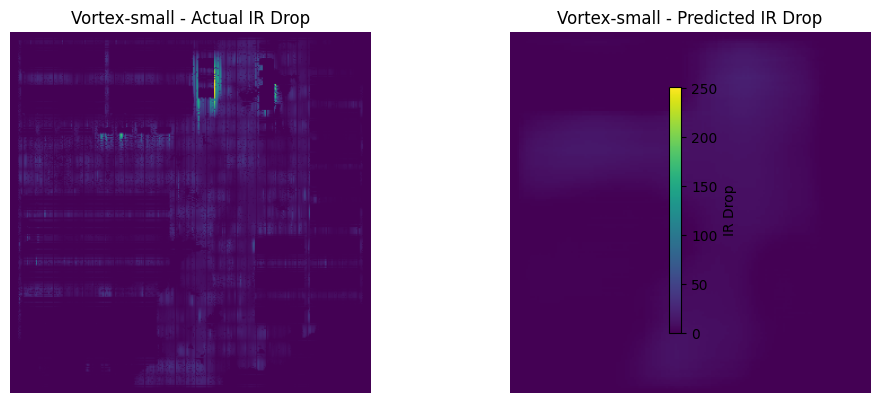

Pred range : -0.874713 29.805079
Truth range: 0.0 388.53348


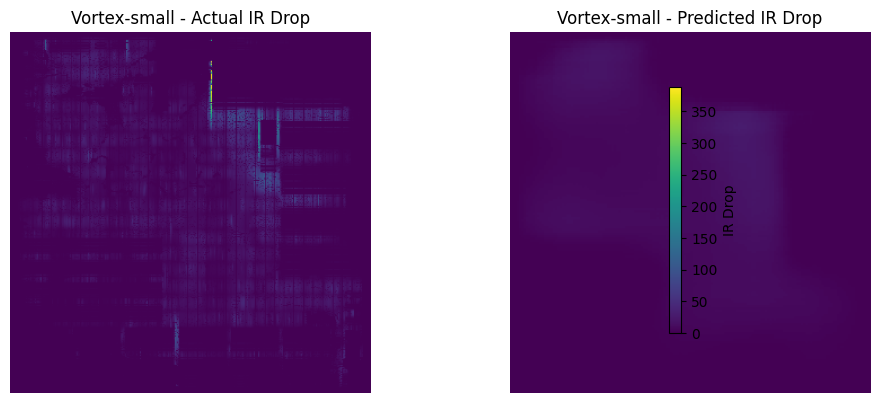

Pred range : -0.88690263 13.202052
Truth range: 0.0 120.3181


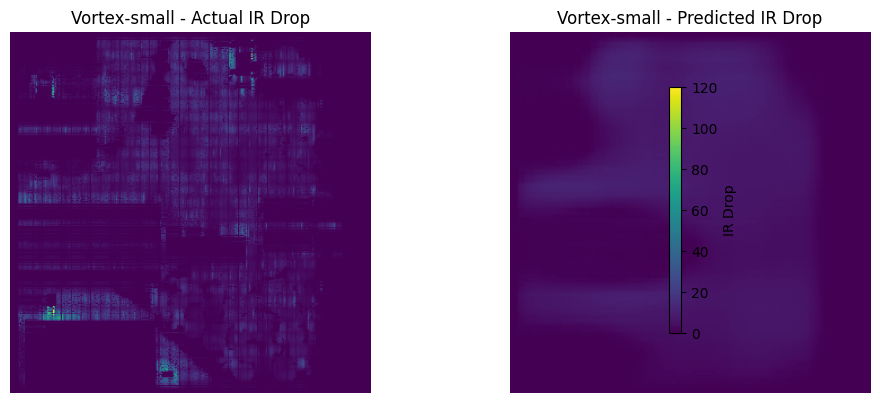

In [19]:
# =========================================================
# IMAGE VISUALIZATION FOR ALL 8 CHIPS
# =========================================================

for chip in CHIPS:

    print("\n===================================")
    print(f"{chip}")
    print("===================================\n")

    indices = chip_sample_indices[chip]

    for idx in indices:

        pred = all_preds[idx][:, :, 0]
        truth = all_truth[idx][:, :, 0]

        print("Pred range :", pred.min(), pred.max())
        print("Truth range:", truth.min(), truth.max())

        # shared color scale
        vmin = 0
        vmax = max(pred.max(), truth.max())

        fig, axes = plt.subplots(1, 2, figsize=(10,4))

        # Ground truth
        im0 = axes[0].imshow(
            truth,
            vmin=vmin,
            vmax=vmax
        )

        axes[0].set_title(f"{chip} - Actual IR Drop")
        axes[0].axis("off")

        # Prediction
        im1 = axes[1].imshow(
            pred,
            vmin=vmin,
            vmax=vmax
        )

        axes[1].set_title(f"{chip} - Predicted IR Drop")
        axes[1].axis("off")

        # Colorbar
        cbar = fig.colorbar(
            im1,
            ax=axes.ravel().tolist(),
            shrink=0.8
        )

        cbar.set_label("IR Drop")

        plt.tight_layout()
        plt.show()


Vortex-small

Pred range : -1.2998921 22.068592
Truth range: 0.0 251.51474


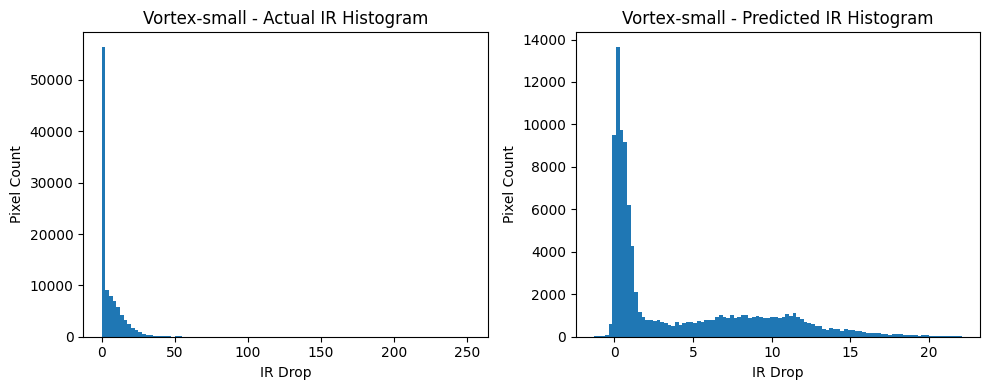

Pred range : -0.874713 29.805079
Truth range: 0.0 388.53348


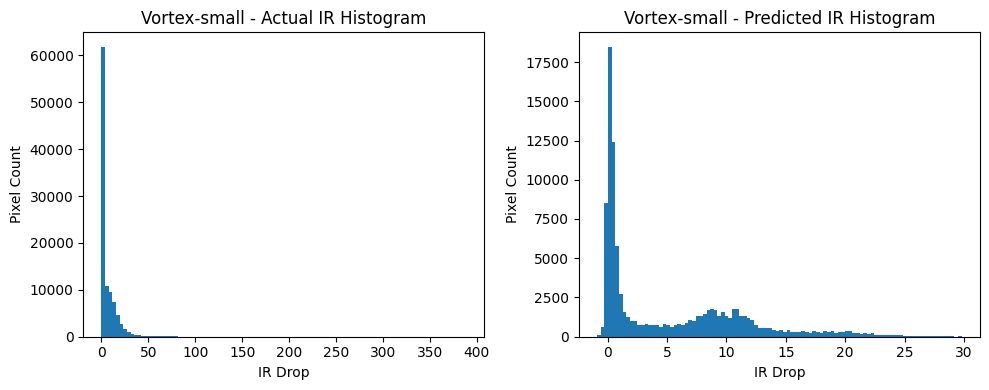

Pred range : -0.88690263 13.202052
Truth range: 0.0 120.3181


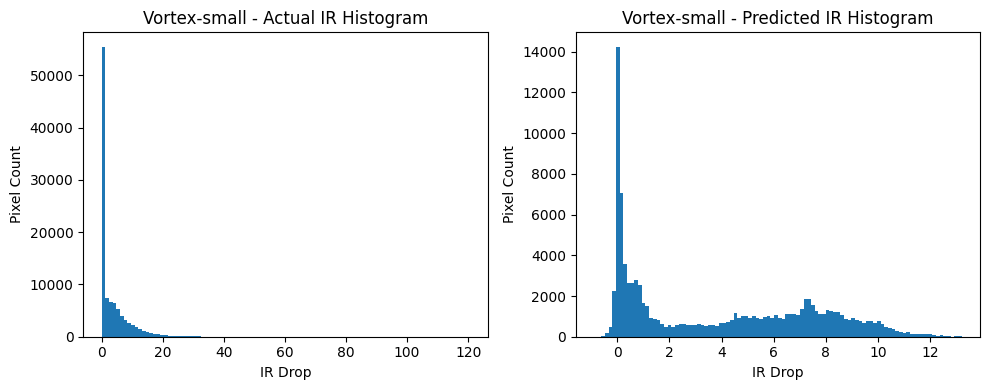

In [20]:
# =========================================================
# HISTOGRAMS FOR ALL 8 CHIPS
# =========================================================

for chip in CHIPS:

    print("\n===================================")
    print(f"{chip}")
    print("===================================\n")

    indices = chip_sample_indices[chip]

    for idx in indices:

        pred = all_preds[idx][:, :, 0]
        truth = all_truth[idx][:, :, 0]

        print("Pred range :", pred.min(), pred.max())
        print("Truth range:", truth.min(), truth.max())

        pred_flat = pred.flatten()
        truth_flat = truth.flatten()

        fig, axes = plt.subplots(1, 2, figsize=(10,4))

        # Actual histogram
        axes[0].hist(
            truth_flat,
            bins=100
        )

        axes[0].set_title(f"{chip} - Actual IR Histogram")
        axes[0].set_xlabel("IR Drop")
        axes[0].set_ylabel("Pixel Count")

        # Predicted histogram
        axes[1].hist(
            pred_flat,
            bins=100
        )

        axes[1].set_title(f"{chip} - Predicted IR Histogram")
        axes[1].set_xlabel("IR Drop")
        axes[1].set_ylabel("Pixel Count")

        plt.tight_layout()
        plt.show()

In [21]:
import json as _json
_sweep_metadata = {'loss': 'LogCosh', 'batch_size': 16, 'learning_rate': 0.001, 'fine_tuned_layers': 10}
_sweep_ssim = float(per_chip_metrics_per_chip['Vortex-small']['SSIM'])
with open('result.json', 'w') as _result_file:
    _json.dump({**_sweep_metadata, 'per_chip_range_ssim': _sweep_ssim}, _result_file, indent=2)
print(f'SWEEP_PER_CHIP_RANGE_SSIM={_sweep_ssim:.9f}')

SWEEP_PER_CHIP_RANGE_SSIM=0.831750393
